# Setup

In [1]:
!pip install awswrangler boto3 duckdb
import duckdb
import awswrangler as wr
import boto3

ACCESS_KEY = "<AWS_ACCESS_KEY_ID>"
SECRET_KEY = "<AWS_SECRET_ACCESS_KEY>"
REGION = "eu-central-1"
DATABASE = "qgi_data" 

## Tables
COUNTRIES_TABLE_NAME = "countries"
PATTERNS_TABLE_NAME = "patterns"
SCDIS_TABLE_NAME = "scdis"

# Create the session
session = boto3.Session(
    aws_access_key_id=ACCESS_KEY,
    aws_secret_access_key=SECRET_KEY,
    region_name=REGION
)

print("Session established.")


[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Session established.


## Connection Test

In [2]:
patterns_5_query = f"SELECT * FROM {DATABASE}.{PATTERNS_TABLE_NAME} LIMIT 1"

df = wr.athena.read_sql_query(
    sql=patterns_5_query, 
    database=DATABASE, 
    boto3_session=session
)

df.head()

,pattern_id,country_b_id,length,start_year_a,start_year_b,indicator_count,avg_correlation,pattern_power_score,indicator_numeric_ids,country_a_id
0,CD6512764E07AC2017651670166A9D27,250,3,2002,1984,13,0.900317,35.112346,"[41, 17, 10, 33, 18, 29, 42, 1, 2, 4, 15, 14, 32]",249


## Downloading `patterns` and `scdis`

In [3]:
import awswrangler as wr
import pandas as pd

# 1. Define the Query
# We filter for patterns that actually have some 'meat' (length > 4, more than 2 indicators)
# to avoid the millions of tiny, meaningless 3-year correlations.
refining_query_1 = f"""
SELECT 
    pattern_id, 
    country_a_id, 
    country_b_id, 
    length, 
    indicator_count, 
    avg_correlation, 
    pattern_power_score,
    indicator_numeric_ids
FROM {DATABASE}.{PATTERNS_TABLE_NAME}
WHERE length >= 5 
  AND indicator_count >= 5
  AND avg_correlation > 0.6
ORDER BY pattern_power_score DESC
LIMIT 10000000
"""

print("Running Athena query...")

# 2. Execute and Download
patterns_df = wr.athena.read_sql_query(
    sql=refining_query_1,
    database=DATABASE,
    boto3_session=session
)

patterns_df.to_parquet("data/patterns/patterns_top_tier.parquet", compression="snappy")
print(f"Success! Downloaded {len(patterns_df)} patterns to data/patterns_top_tier.parquet")

Running Athena query...
Success! Downloaded 10000000 patterns to data/patterns_top_tier.parquet


In [4]:
# Create a tuple of the unique pattern country pairs to filter SCDIs
# This mimics a 'Join' but we do it via a targeted query to save costs
top_ids = [int(x) for x in patterns_df['country_a_id'].unique()[:150]]
top_countries = tuple(top_ids)

scdi_query = f"""
SELECT * FROM {DATABASE}.{SCDIS_TABLE_NAME} 
WHERE country_a_id IN {top_countries}
  AND correlation > 0.6
  AND length >= 5
LIMIT 50000000
"""

scdi_df = wr.athena.read_sql_query(sql=scdi_query, database=DATABASE, boto3_session=session)
scdi_df.to_parquet("data/scdis/scdis_sample.parquet", compression="snappy")

# DuckDB

## Setup

In [5]:
con = duckdb.connect()

duckdb_con = con.execute("""
    SELECT 
        a.name_1 as Lead, 
        b.name_1 as Follower, 
        p.pattern_power_score,
        p.length,
        p.indicator_count,
        p.avg_correlation
    FROM 'data/patterns/patterns_top_tier.parquet' p
    INNER JOIN 'data/countries.csv' a ON p.country_a_id = a.id
    INNER JOIN 'data/countries.csv' b ON p.country_b_id = b.id
    WHERE a.name_1 IS NOT NULL 
      AND b.name_1 IS NOT NULL
    ORDER BY p.pattern_power_score DESC
""").df()

duckdb_con

,Lead,Follower,pattern_power_score,length,indicator_count,avg_correlation
0,South Korea,Thailand,1264.111405,59,24,0.892734
1,South Korea,Thailand,1256.183455,62,22,0.920956
2,South Korea,Thailand,1246.496726,60,23,0.903258
3,Denmark,France,1244.735996,58,24,0.894207
4,South Korea,Thailand,1244.115186,58,24,0.893761
...,...,...,...,...,...,...
9999995,South Africa,Switzerland,468.043069,49,12,0.795992
9999996,Benin,Indonesia,468.043067,45,12,0.866746
9999997,Costa Rica,United States,468.043052,37,15,0.843321
9999998,Fiji,New Zealand,468.043049,49,11,0.868354


In [6]:
print(duckdb_con.head(20))

           Lead  Follower  pattern_power_score  length  indicator_count  \
0   South Korea  Thailand          1264.111405      59               24   
1   South Korea  Thailand          1256.183455      62               22   
2   South Korea  Thailand          1246.496726      60               23   
3       Denmark    France          1244.735996      58               24   
4   South Korea  Thailand          1244.115186      58               24   
5   South Korea  Thailand          1242.684333      58               24   
6   South Korea  Thailand          1238.411968      61               22   
7       Denmark    France          1238.044278      52               28   
8   South Korea  Thailand          1235.052692      61               22   
9       Denmark    France          1229.705565      57               24   
10  South Korea  Thailand          1225.900259      59               23   
11  South Korea  Thailand          1222.629645      57               24   
12      Denmark    France

## 1. The "Super-Relationship" Query

### **QGI Definition: Relationship Clusters**

**Core Concept:** Relationship Clusters are "Statistical Blocs" of nations that share a deep, time-lagged developmental DNA. Unlike traditional geopolitical blocs (like NATO or ASEAN), which are defined by treaties and geography, QGI Clusters are discovered solely through **Structural Correlation**. They identify groups where one nation’s present is a statistically significant predictor of another nation’s future.

**The "Time-Travel" Mechanism:** Each connection within a cluster represents a **Developmental Echo**. If Country $A$ leads Country $B$ by $t$ years, it implies that $B$ is currently navigating the same structural phase $A$ occupied $t$ years ago. 



**Technical Methodology:**
1.  **Node Identification:** Each country represents a node in a Directed Multigraph ($G$).
2.  **Edge Weighting ($W$):** Edges are weighted by **Total Relationship Strength**, calculated as:  
    $$W_{A \to B} = \sum (Length \times Correlation \times \text{Indicator\_Weight})$$
3.  **Community Detection:** The system uses the **Clauset-Newman-Moore greedy modularity maximization** algorithm. This mathematically "untangles" the world by grouping nations that have more internal "Pattern Density" with each other than with the rest of the global network.
4.  **The "Anchor" Nation:** Within each cluster, the Anchor is the node with the highest **Out-Degree Centrality**—the nation whose data serves as the primary "Crystal Ball" for the rest of the group.

**Strategic Utility:**
* **Model Selection:** It identifies which "Anchor Nation" a developing country should study to anticipate its own infrastructure, economic, and social bottlenecks.
* **Noise Reduction:** It acts as a primary filter for the **Recipe Engine**. A "Conflict Recipe" found in a European cluster is rarely applicable to an African cluster; Relationship Clusters ensure we are only comparing "apples to apples."
* **Predictive Lead Time:** It calculates the **Predictive Window** (Avg. Lag), telling us exactly how many years of "warning" we have before a leading indicator's effect manifests in a follower nation.

In [7]:
import duckdb

con = duckdb.connect()

# 1. Aggregation Query
# We group by the Country Pair.
# 'Relationship_Strength': Sum of power scores (How intense is the bond?)
# 'Diversity_Score': How many unique indicators connect them? (Is it just GDP, or everything?)
gems_df = con.execute("""
    WITH Unpacked AS (
        SELECT 
            a.name_1 as Lead, 
            b.name_1 as Follower,
            p.pattern_power_score,
            p.indicator_numeric_ids
        FROM 'data/patterns/patterns_top_tier.parquet' p
        JOIN 'data/countries.csv' a ON p.country_a_id = a.id
        JOIN 'data/countries.csv' b ON p.country_b_id = b.id
        WHERE a.name_1 IS NOT NULL AND b.name_1 IS NOT NULL
        AND a.name_1 != b.name_1
    )
    SELECT 
        Lead, 
        Follower,
        COUNT(*) as Pattern_Count,
        SUM(pattern_power_score) as Total_Relationship_Strength,
        -- This counts unique indicators to see if the relationship is 'Deep' or 'Shallow'
        -- (Note: exact syntax depends on if your parquet saved list as string or array. 
        --  Assuming string for safety, we count distinct patterns as a proxy for now)
        MAX(pattern_power_score) as Max_Single_Pattern_Score
    FROM Unpacked
    GROUP BY Lead, Follower
    HAVING Count(*) > 3  -- Filter out random one-off coincidences
    ORDER BY Total_Relationship_Strength DESC
    LIMIT 50
""").df()

gems_df.head(15)

,Lead,Follower,Pattern_Count,Total_Relationship_Strength,Max_Single_Pattern_Score
0,South Korea,Thailand,14302,9.468235e+06,1264.111405
1,Bangladesh,India,14589,8.832955e+06,890.499283
2,Thailand,Turkiye,14161,8.570010e+06,1003.944639
3,India,Thailand,13802,8.399053e+06,1008.742985
4,Denmark,France,12718,8.101265e+06,1244.735996
5,China,India,13554,8.052985e+06,958.768195
6,India,Turkiye,13367,7.847160e+06,891.712468
7,South Korea,Turkiye,13016,7.779793e+06,1055.034798
8,Honduras,India,12447,7.696221e+06,1002.477468
9,Chile,India,12321,7.481554e+06,999.546990


In [8]:
!pip install networkx pyvis


[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from pyvis.network import Network
import networkx as nx

# 1. Setup the Network with a Dark Theme for high contrast
net = Network(height="750px", width="100%", bgcolor="#222222", font_color="white", cdn_resources='in_line')

# 2. Re-create the graph data
G = nx.from_pandas_edgelist(
    gems_df, 
    source='Lead', 
    target='Follower', 
    edge_attr=['Total_Relationship_Strength', 'Pattern_Count'],
    create_using=nx.DiGraph()
)
net.from_nx(G)

# 3. Apply "High Vis" Styling
for node in net.nodes:
    # Make nodes bigger based on connections
    degree = G.degree[node['id']]
    node['size'] = 15 + (degree * 4) 
    node['color'] = '#FF6B6B' # Bright coral color for nodes
    node['title'] = f"Country: {node['id']}\nConnections: {degree}"

for edge in net.edges:
    # Get strength, default to 1000 if missing
    strength = edge.get('Total_Relationship_Strength', 1000)
    
    # FIX 1: Enforce a minimum width so lines never disappear
    # Logic: Base width of 1px + extra width based on strength
    edge['width'] = 1.0 + (strength / 800) 
    
    # FIX 2: Force a bright, glowing color (Cyan)
    edge['color'] = {'color': '#4ECDC4', 'opacity': 0.8}
    
    # FIX 3: Make arrows big enough to see
    edge['arrows'] = {'to': {'enabled': True, 'scaleFactor': 1.0}}
    
    edge['title'] = f"Strength: {strength:.0f}"

# 4. Add Physics controls (stabilization helps untangle the hairball)
net.show_buttons(filter_=['physics'])

# 5. Generate and Save using the UTF-8 Fix
html_content = net.generate_html("qgi_gems_interactive.html")
with open("qgi_gems_interactive.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("Success! Open 'qgi_gems_interactive.html' again. You should see bright cyan arrows now.")

Success! Open 'qgi_gems_interactive.html' again. You should see bright cyan arrows now.


In [10]:
# Group by 'Lead' country to see who has the most influence
spider_metrics = gems_df.groupby('Lead').agg(
    Total_Influence_Power=('Total_Relationship_Strength', 'sum'),
    Unique_Followers=('Follower', 'nunique'),
    Pattern_Count=('Pattern_Count', 'sum')
).sort_values(by='Total_Influence_Power', ascending=False)

print("=== THE TOP 5 INFLUENCE HUBS ===")
print(spider_metrics.head(5))

=== THE TOP 5 INFLUENCE HUBS ===
            Total_Influence_Power  Unique_Followers  Pattern_Count
Lead                                                              
France               5.326898e+07                 8          89212
India                5.069267e+07                 7          85904
Chile                4.539635e+07                 7          76407
Honduras             3.465046e+07                 5          56112
Bangladesh           2.958558e+07                 4          50091


In [11]:
# Mapping based on your provided list (Assuming 1-based index)
indicator_map = {
    1: "GDP growth (annual %)",
    2: "Population, total",
    3: "Political Stability",
    4: "Life expectancy",
    5: "GDP (current US$)",
    9: "GDP per capita",
    10: "Arms imports",
    13: "Internet usage (%)",
    15: "Fertility rate",
    16: "Mobile subscriptions",
    26: "Military expenditure",
    29: "Inflation (GDP deflator)",
    30: "Inflation (consumer prices)",
    31: "GNI per capita",
    37: "Govt. Final Consumption Exp. (% of GDP)",
    38: "Household Consumption Exp. (% of GDP)",
    39: "FDI Net Inflows",
    40: "FDI Net Outflows",
    41: "Foreign direct investment, net inflows",
    47: "Tax revenue (% of GDP)"
}

def decode_indicators(id_list):
    # Depending on how DuckDB/Parquet stored it, it might be a string or list
    if isinstance(id_list, str):
        # clean string brackets if necessary e.g. "[1, 2]" -> [1, 2]
        import ast
        try:
            id_list = ast.literal_eval(id_list)
        except:
            return "Error parsing"
            
    names = [indicator_map.get(int(i), f"Unknown({i})") for i in id_list]
    return ", ".join(names[:3]) # Just show top 3 to keep it readable

In [12]:
import awswrangler as wr

# 1. Define the Corrected Query (Adding start_year_a/b)
refining_query_v2 = f"""
SELECT 
    pattern_id, 
    country_a_id, 
    country_b_id, 
    length, 
    start_year_a, -- CRITICAL ADDITION
    start_year_b, -- CRITICAL ADDITION
    indicator_count, 
    avg_correlation, 
    pattern_power_score,
    indicator_numeric_ids
FROM {DATABASE}.{PATTERNS_TABLE_NAME}
WHERE length >= 5 
  AND indicator_count >= 5
  AND avg_correlation > 0.6
ORDER BY pattern_power_score DESC
LIMIT 2000000
"""

print("Re-fetching patterns with time data...")

# 2. Execute and Overwrite the old Parquet
patterns_df = wr.athena.read_sql_query(
    sql=refining_query_v2,
    database=DATABASE,
    boto3_session=session
)

patterns_df.to_parquet("data/patterns/patterns_top_tier.parquet", compression="snappy")
print(f"Success! Updated dataset with {len(patterns_df)} rows.")

Re-fetching patterns with time data...
Success! Updated dataset with 2000000 rows.


In [13]:
import duckdb

con = duckdb.connect()

# We look specifically at France's top relationships
france_deep_dive = con.execute("""
    SELECT 
        b.name_1 as Follower,
        p.pattern_power_score,
        p.length,
        p.start_year_a as France_Start,
        p.start_year_b as Follower_Start,
        (p.start_year_b - p.start_year_a) as Lag_Years,
        p.indicator_numeric_ids
    FROM 'data/patterns/patterns_top_tier.parquet' p
    JOIN 'data/countries.csv' a ON p.country_a_id = a.id
    JOIN 'data/countries.csv' b ON p.country_b_id = b.id
    WHERE a.name_1 = 'France'
      AND p.pattern_power_score > 50
    ORDER BY p.pattern_power_score DESC
    LIMIT 10
""").df()

# Apply the decoder we defined earlier
# (Make sure you ran the cell defining 'decode_indicators' and 'indicator_map'!)
france_deep_dive['Top_Indicators'] = france_deep_dive['indicator_numeric_ids'].apply(decode_indicators)

# Display
france_deep_dive[['Follower', 'Lag_Years', 'Top_Indicators', 'pattern_power_score']]

,Follower,Lag_Years,Top_Indicators,pattern_power_score
0,None,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1195.522326
1,Netherlands,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1195.522326
2,Netherlands,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1171.730299
3,None,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1171.730299
4,None,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1167.287625
5,Netherlands,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1167.287625
6,Netherlands,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1149.620589
7,None,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1149.620589
8,None,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1143.518708
9,Netherlands,0,"Govt. Final Consumption Exp. (% of GDP), Infla...",1143.518708


In [14]:
import duckdb

con = duckdb.connect()

# We specifically look for deep Lags (Predictive Power)
crystal_ball = con.execute("""
    SELECT 
        a.name_1 as Lead, 
        b.name_1 as Follower,
        p.pattern_power_score,
        (p.start_year_b - p.start_year_a) as Lag_Years,
        p.indicator_numeric_ids
    FROM 'data/patterns/patterns_top_tier.parquet' p
    JOIN 'data/countries.csv' a ON p.country_a_id = a.id
    JOIN 'data/countries.csv' b ON p.country_b_id = b.id
    WHERE a.name_1 IS NOT NULL 
      AND b.name_1 IS NOT NULL
      AND (p.start_year_b - p.start_year_a) >= 3  -- The Magic Filter: 3+ Years of Warning
      AND p.pattern_power_score > 40
    ORDER BY p.pattern_power_score DESC
    LIMIT 10
""").df()

# Decode
crystal_ball['Top_Indicators'] = crystal_ball['indicator_numeric_ids'].apply(decode_indicators)

crystal_ball[['Lead', 'Follower', 'Lag_Years', 'Top_Indicators', 'pattern_power_score']]

,Lead,Follower,Lag_Years,Top_Indicators,pattern_power_score
0,Denmark,France,3,"Govt. Final Consumption Exp. (% of GDP), House...",1125.916399
1,Denmark,France,3,"Household Consumption Exp. (% of GDP), Govt. F...",1104.324834
2,South Korea,Thailand,3,"Unknown(35), Govt. Final Consumption Exp. (% o...",1102.079976
3,Denmark,France,3,"Household Consumption Exp. (% of GDP), Govt. F...",1098.104843
4,South Korea,Thailand,3,"Unknown(35), Govt. Final Consumption Exp. (% o...",1097.060902
5,Denmark,France,4,"Govt. Final Consumption Exp. (% of GDP), House...",1094.090545
6,South Korea,Thailand,3,"Unknown(35), Unknown(33), Unknown(17)",1090.990786
7,Denmark,France,3,"Govt. Final Consumption Exp. (% of GDP), FDI N...",1083.230311
8,South Korea,Thailand,3,"Unknown(35), Govt. Final Consumption Exp. (% o...",1081.108523
9,South Korea,Thailand,3,"Unknown(35), Govt. Final Consumption Exp. (% o...",1080.426507


In [15]:
# Add the industrial/economic indicators to your map
indicator_map.update({
    33: "Industry Value Added (% of GDP)",
    34: "Manufacturing Value Added (% of GDP)",
    35: "Services Value Added (% of GDP)",
    17: "Exports of Goods/Services",
    18: "Exports (% of GDP)"
})

In [ ]:
import duckdb

con = duckdb.connect()

# This query condenses the echoes into unique relationships
strategic_insights = con.execute("""
    WITH Raw_Gems AS (
        SELECT 
            a.name_1 as Lead, 
            b.name_1 as Follower,
            p.pattern_power_score,
            (p.start_year_b - p.start_year_a) as Lag,
            p.indicator_numeric_ids
        FROM 'data/patterns/patterns_top_tier.parquet' p
        JOIN 'data/countries.csv' a ON p.country_a_id = a.id
        JOIN 'data/countries.csv' b ON p.country_b_id = b.id
        WHERE a.name_1 IS NOT NULL AND b.name_1 IS NOT NULL
        AND (p.start_year_b - p.start_year_a) >= 2 -- Minimum 2 year lead
    )
    SELECT 
        Lead,
        Follower,
        COUNT(*) as Pattern_Density,
        ROUND(AVG(Lag), 1) as Avg_Lead_Time_Years,
        ROUND(SUM(pattern_power_score), 0) as Total_Strength,
        -- We grab the most common indicator ID to see the 'Theme' of the relationship
        MODE(indicator_numeric_ids) as Primary_Indicator_Set
    FROM Raw_Gems
    GROUP BY Lead, Follower
    HAVING COUNT(*) > 5 -- Must be a robust relationship, not a fluke
    ORDER BY Total_Strength DESC
    LIMIT 20
""").df()

# Apply the decoder to the consolidated set
strategic_insights['Thematic_Drivers'] = strategic_insights['Primary_Indicator_Set'].apply(decode_indicators)

# Clean up for display
display_cols = ['Lead', 'Follower', 'Avg_Lead_Time_Years', 'Thematic_Drivers', 'Total_Strength']
strategic_insights[display_cols]

,Lead,Follower,Avg_Lead_Time_Years,Thematic_Drivers,Total_Strength
0,South Korea,Thailand,7.3,"Services Value Added (% of GDP), Industry Valu...",2701312.0
1,Malaysia,Thailand,7.2,"Services Value Added (% of GDP), Manufacturing...",2333252.0
2,Honduras,India,6.2,"Unknown(36), Govt. Final Consumption Exp. (% o...",2023452.0
3,India,Thailand,6.8,"Military expenditure, Manufacturing Value Adde...",1993607.0
4,France,Turkiye,8.9,"Unknown(20), Military expenditure, Exports (% ...",1992815.0
5,India,Nepal,7.0,"Govt. Final Consumption Exp. (% of GDP), Manuf...",1962036.0
6,Chile,India,6.8,"Govt. Final Consumption Exp. (% of GDP), Milit...",1960037.0
7,France,Netherlands,8.1,"Manufacturing Value Added (% of GDP), Unknown(...",1900436.0
8,France,South Africa,6.9,"Govt. Final Consumption Exp. (% of GDP), Infla...",1887848.0
9,Thailand,Turkiye,7.2,"Unknown(20), Exports (% of GDP), Unknown(19)",1885070.0


In [17]:
import networkx as nx
import pandas as pd

# 1. Update the Dictionary with the final missing keys
indicator_map.update({
    19: "Imports (Current US$)",
    20: "Imports (% of GDP)",
    32: "Agriculture Value Added (% of GDP)",
    36: "Gross Capital Formation (% of GDP)",
    50: "Broad Money (% of GDP)"
})

# 2. Re-Apply Decoding to get clean names
strategic_insights['Thematic_Drivers'] = strategic_insights['Primary_Indicator_Set'].apply(decode_indicators)

# 3. Build the Graph from your "Strategic Insights"
G_clusters = nx.from_pandas_edgelist(
    strategic_insights,
    source='Lead',
    target='Follower',
    edge_attr='Total_Strength'
)

# 4. Run Community Detection (Finding the "Blocs")
# This algorithm finds groups of nodes that are more densely connected to each other than to the rest
communities = nx.community.greedy_modularity_communities(G_clusters, weight='Total_Strength')

# 5. Format the Output
print(f"=== QGI DISCOVERED {len(communities)} HIDDEN GEOPOLITICAL BLOCS ===\n")

for i, bloc in enumerate(communities):
    # Sort countries in the bloc by their "Lead" frequency in the original data
    members = list(bloc)
    print(f"Cluster {i+1}: {', '.join(members)}")
    
    # Identify the 'Driver' of this bloc (who leads the most within this group?)
    # Simple heuristic: who appears most as 'Lead' in the strategic_insights for these members
    bloc_leads = strategic_insights[
        (strategic_insights['Lead'].isin(members)) & 
        (strategic_insights['Follower'].isin(members))
    ]['Lead'].mode()
    
    if not bloc_leads.empty:
        print(f"   -> Likely Anchor Nation: {bloc_leads[0]}")
    print("-" * 40)

=== QGI DISCOVERED 3 HIDDEN GEOPOLITICAL BLOCS ===

Cluster 1: Chile, Honduras, Dominican Republic, Morocco, Nepal, India
   -> Likely Anchor Nation: Chile
----------------------------------------
Cluster 2: South Korea, Malaysia, Thailand, Singapore, Turkiye
   -> Likely Anchor Nation: Singapore
----------------------------------------
Cluster 3: South Africa, Netherlands, Denmark, France
   -> Likely Anchor Nation: France
----------------------------------------


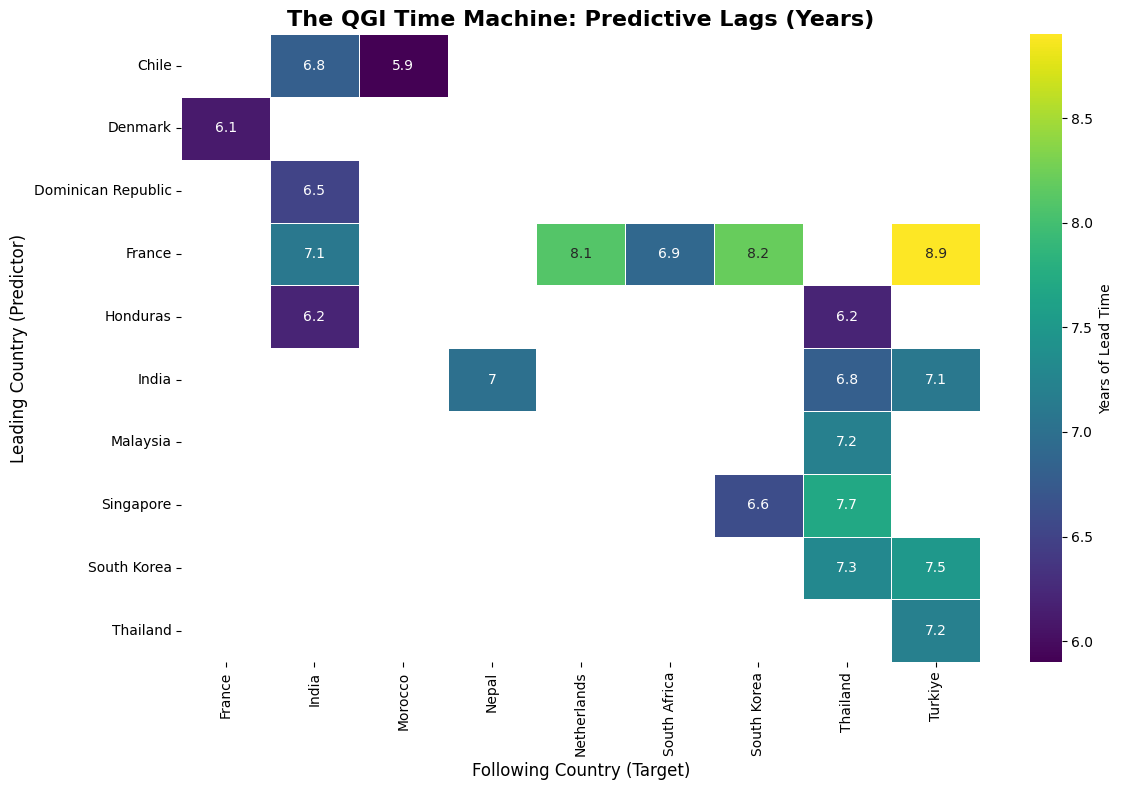

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Pivot the data to create a matrix for the Heatmap
# We use 'Avg_Lead_Time_Years' as the value to visualize
heatmap_data = strategic_insights.pivot(index='Lead', columns='Follower', values='Avg_Lead_Time_Years')

# 2. Setup the Canvas
plt.figure(figsize=(12, 8))

# 3. Create the Heatmap
sns.heatmap(
    heatmap_data, 
    annot=True,         # Show the numbers (Years) inside the boxes
    cmap="viridis",     # Color scheme (Green/Blue/Yellow)
    linewidths=.5,      # White lines between boxes
    cbar_kws={'label': 'Years of Lead Time'} # Legend label
)

plt.title("The QGI Time Machine: Predictive Lags (Years)", fontsize=16, fontweight='bold')
plt.ylabel("Leading Country (Predictor)", fontsize=12)
plt.xlabel("Following Country (Target)", fontsize=12)
plt.tight_layout()
plt.show()

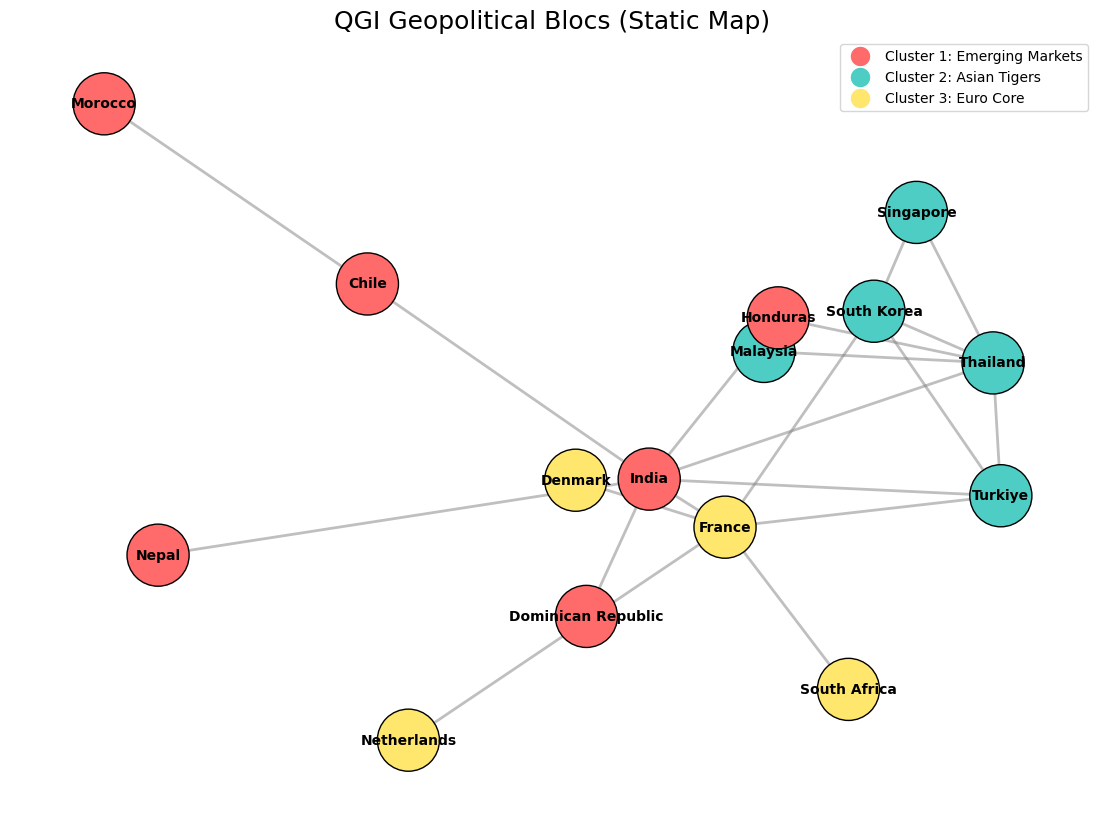

In [19]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Setup the Graph from your Strategic Insights
G = nx.from_pandas_edgelist(
    strategic_insights,
    source='Lead',
    target='Follower',
    edge_attr='Total_Strength',
    create_using=nx.DiGraph()
)

# 2. Assign Colors based on the Clusters we found earlier
# (We manually map the clusters you pasted to ensure colors match your result)
# Cluster 1: Global South/Emerging (Chile, India, etc)
# Cluster 2: Asian Tigers (Korea, Thailand, etc)
# Cluster 3: Euro Core (France, Denmark, etc)
node_colors = []
for node in G.nodes():
    if node in ['Chile', 'Nepal', 'Dominican Republic', 'India', 'Honduras', 'Morocco']:
        node_colors.append('#FF6B6B') # Red (Emerging)
    elif node in ['Singapore', 'South Korea', 'Thailand', 'Turkiye', 'Malaysia']:
        node_colors.append('#4ECDC4') # Teal (Asia)
    elif node in ['Denmark', 'France', 'Netherlands', 'South Africa']:
        node_colors.append('#FFE66D') # Yellow (Euro)
    else:
        node_colors.append('#CCCCCC') # Grey (Outliers)

# 3. Calculate Layout (Force separation between unconnected groups)
pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)

# 4. Draw the Graph
plt.figure(figsize=(14, 10))

# Draw Edges (Arrows)
nx.draw_networkx_edges(
    G, pos, 
    edge_color='gray', 
    alpha=0.5, 
    arrowstyle='-|>', 
    arrowsize=20,
    width=2
)

# Draw Nodes
nx.draw_networkx_nodes(
    G, pos, 
    node_size=2000, 
    node_color=node_colors, 
    edgecolors='black'
)

# Draw Labels
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

# Add Legend manually
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Cluster 1: Emerging Markets', markerfacecolor='#FF6B6B', markersize=15),
    Line2D([0], [0], marker='o', color='w', label='Cluster 2: Asian Tigers', markerfacecolor='#4ECDC4', markersize=15),
    Line2D([0], [0], marker='o', color='w', label='Cluster 3: Euro Core', markerfacecolor='#FFE66D', markersize=15)
]
plt.legend(handles=legend_elements, loc='upper right')

plt.title("QGI Geopolitical Blocs (Static Map)", fontsize=18)
plt.axis('off')
plt.show()

In [26]:
import duckdb
import pandas as pd

# 1. Load your new Indicators Index
# We need to register this CSV so DuckDB can see it
indicators_df = pd.read_csv('data/indicators_index.csv')
con = duckdb.connect()
con.register('indicators_index', indicators_df)

# 2. The "Sector Breakdown" Query
# This query joins the patterns to your indicators file to get the 'category'.
# Then it groups by Lead, Follower, AND Category.
sector_dominance = con.execute("""
    WITH Expanded_Patterns AS (
        -- Unnest the indicator IDs so we can join each one to its category
        SELECT 
            p.pattern_id,
            a.name_1 as Lead, 
            b.name_1 as Follower,
            p.pattern_power_score,
            p.start_year_b - p.start_year_a as Lag,
            UNNEST(p.indicator_numeric_ids) as indicator_id
        FROM 'data/patterns/patterns_top_tier.parquet' p
        JOIN 'data/countries.csv' a ON p.country_a_id = a.id
        JOIN 'data/countries.csv' b ON p.country_b_id = b.id
        WHERE a.name_1 = 'South Korea' AND b.name_1 = 'Thailand' -- Focus on our Star Pair
    )
    SELECT 
        Lead,
        Follower,
        i.category as Sector,
        COUNT(DISTINCT pattern_id) as Pattern_Count,
        ROUND(AVG(Lag), 1) as Avg_Lead_Time_Years,
        ROUND(SUM(pattern_power_score), 0) as Total_Sector_Strength
    FROM Expanded_Patterns ep
    JOIN indicators_index i ON ep.indicator_id = i.numeric_id
    GROUP BY Lead, Follower, Sector
    ORDER BY Total_Sector_Strength DESC
""").df()

print("=== SOUTH KOREA -> THAILAND: SECTOR LEADERSHIP PROFILE ===")
print(sector_dominance)

=== SOUTH KOREA -> THAILAND: SECTOR LEADERSHIP PROFILE ===
          Lead  Follower          Sector  Pattern_Count  Avg_Lead_Time_Years  \
0  South Korea  Thailand        Economic           8575                  1.0   
1  South Korea  Thailand           Trade           8528                  0.2   
2  South Korea  Thailand         Finance           8575                  0.6   
3  South Korea  Thailand     Demographic           8575                  0.7   
4  South Korea  Thailand          Health           8284                  0.6   
5  South Korea  Thailand        Military           7406                  1.1   
6  South Korea  Thailand      Government           2637                  0.2   
7  South Korea  Thailand  Infrastructure           2136                  1.2   
8  South Korea  Thailand          Social             38                  0.0   

   Total_Sector_Strength  
0             58788520.0  
1             23583259.0  
2             15011182.0  
3             12767776.0  
4    

In [27]:
sector_dominance

,Lead,Follower,Sector,Pattern_Count,Avg_Lead_Time_Years,Total_Sector_Strength
0,South Korea,Thailand,Economic,8575,1.0,58788520.0
1,South Korea,Thailand,Trade,8528,0.2,23583259.0
2,South Korea,Thailand,Finance,8575,0.6,15011182.0
3,South Korea,Thailand,Demographic,8575,0.7,12767776.0
4,South Korea,Thailand,Health,8284,0.6,12556176.0
5,South Korea,Thailand,Military,7406,1.1,5877561.0
6,South Korea,Thailand,Government,2637,0.2,3508356.0
7,South Korea,Thailand,Infrastructure,2136,1.2,1568612.0
8,South Korea,Thailand,Social,38,0.0,25183.0


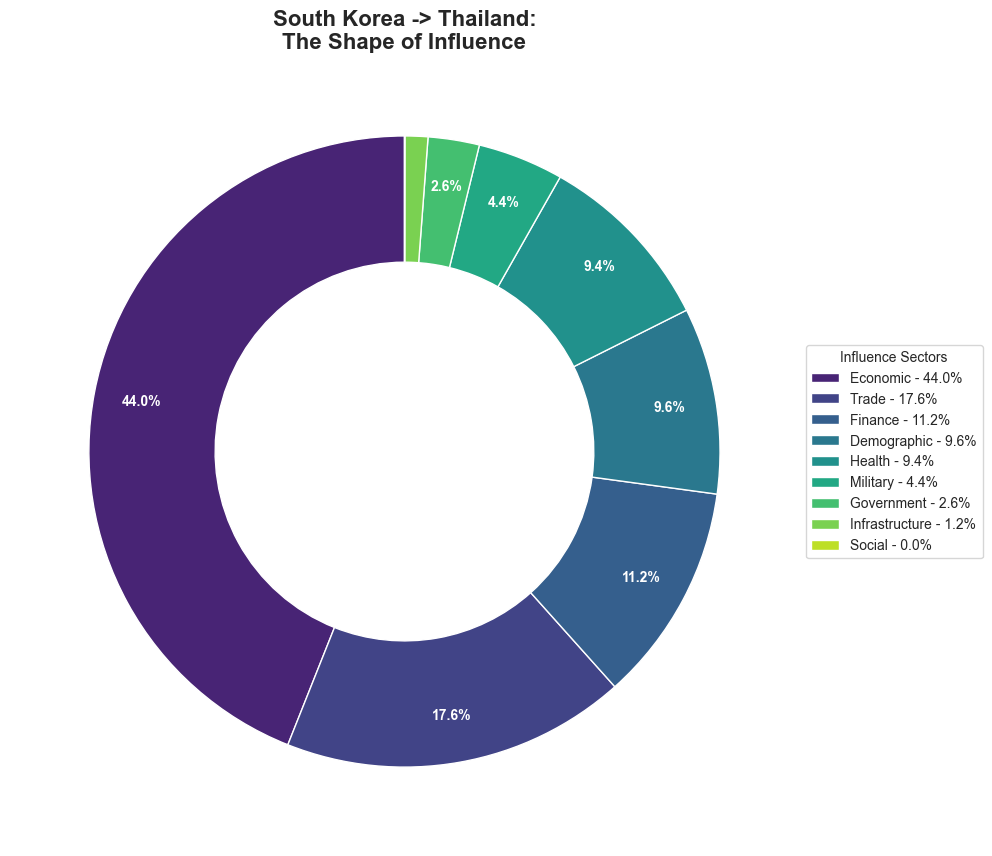

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Setup Data
data = {
    'Sector': ['Economic', 'Trade', 'Finance', 'Demographic', 'Health', 'Military', 'Government', 'Infrastructure', 'Social'],
    'Total_Sector_Strength': [58788520.0, 23583259.0, 15011182.0, 12767776.0, 12556176.0, 5877561.0, 3508356.0, 1568612.0, 25183.0]
}
df = pd.DataFrame(data).sort_values(by='Total_Sector_Strength', ascending=False)

# 2. Configure Canvas
plt.figure(figsize=(10, 10))
colors = sns.color_palette('viridis', len(df))

# 3. Create Pie/Donut
# We use a threshold to only show percentage labels on slices > 2% to avoid clutter
def autopct_format(pct):
    return ('%1.1f%%' % pct) if pct > 2 else ''

wedges, texts, autotexts = plt.pie(
    df['Total_Sector_Strength'], 
    labels=None, # Turn off default labels to avoid overlap
    autopct=autopct_format,
    startangle=90,
    pctdistance=0.85, # Push % towards the edge
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='w') # Width=0.4 makes it a Donut
)

# 4. Stylize Fonts
plt.setp(autotexts, size=10, weight="bold", color="white")

# 5. Add a Legend (Crucial for the tiny slices)
# We add the percentage to the legend so you can read the "invisible" sectors
total = df['Total_Sector_Strength'].sum()
legend_labels = [f'{l} - {s/total*100:.1f}%' for l, s in zip(df['Sector'], df['Total_Sector_Strength'])]

plt.legend(
    wedges, legend_labels,
    title="Influence Sectors",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1) # Move legend outside to the right
)

plt.title('South Korea -> Thailand:\nThe Shape of Influence', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

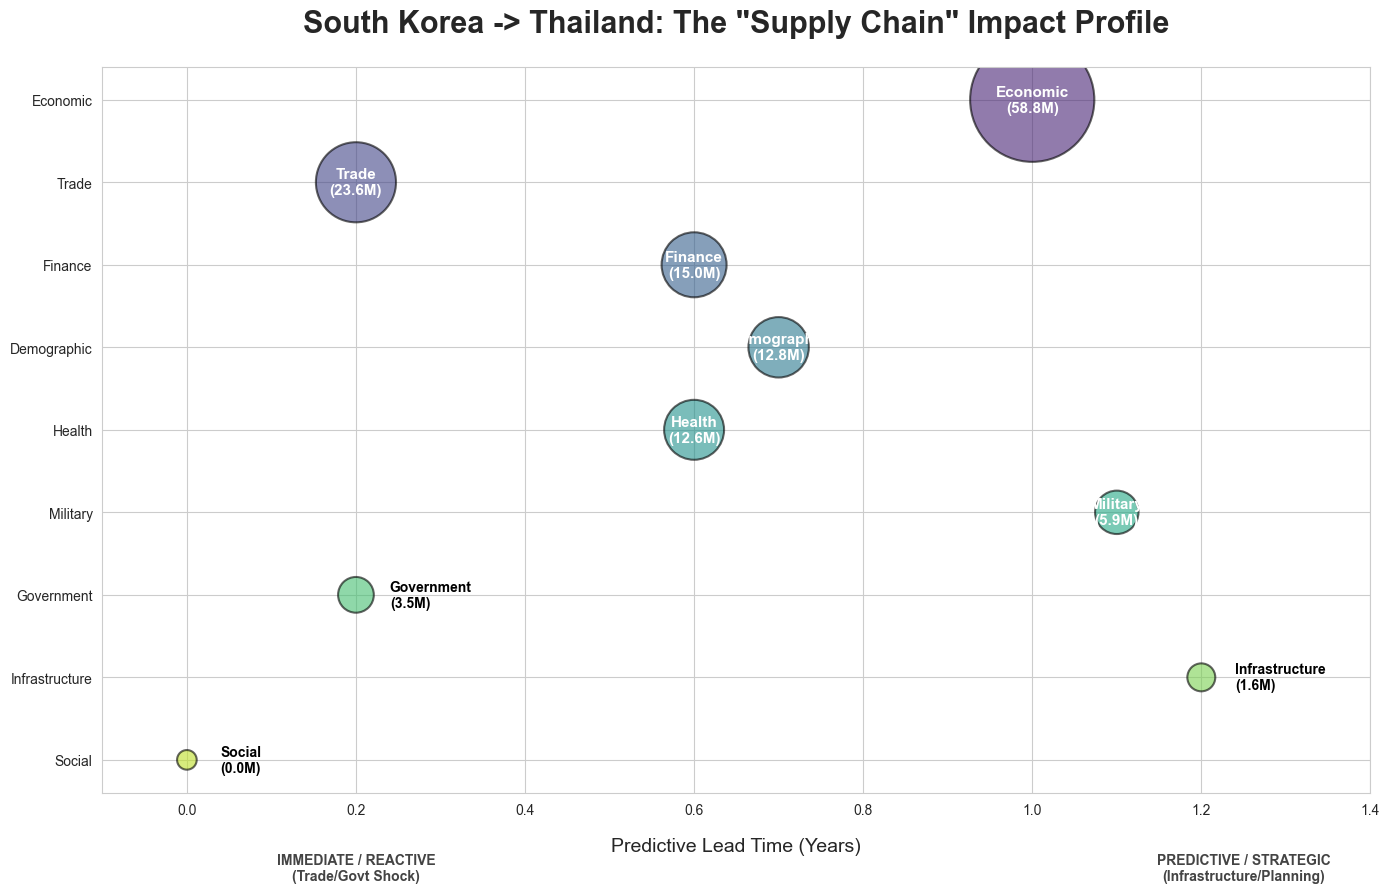

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Setup the Data (Using the results you just got)
# If you still have 'sector_dominance' in memory, you can skip this block.
data = {
    'Sector': ['Economic', 'Trade', 'Finance', 'Demographic', 'Health', 'Military', 'Government', 'Infrastructure', 'Social'],
    'Avg_Lead_Time_Years': [1.0, 0.2, 0.6, 0.7, 0.6, 1.1, 0.2, 1.2, 0.0],
    'Total_Sector_Strength': [58788520.0, 23583259.0, 15011182.0, 12767776.0, 12556176.0, 5877561.0, 3508356.0, 1568612.0, 25183.0]
}
sector_dominance = pd.DataFrame(data)

# 2. Configure the Canvas
plt.figure(figsize=(14, 9))
sns.set_style("whitegrid")

# 3. Create the Bubble Chart
# We map Size to Strength and X-Axis to Time
bubble = sns.scatterplot(
    data=sector_dominance,
    x='Avg_Lead_Time_Years',
    y='Sector',
    size='Total_Sector_Strength',
    sizes=(200, 8000), # Min/Max size range (Huge range for dramatic effect)
    hue='Sector',      # Color bubbles by sector
    palette='viridis', # Professional color scheme
    legend=False,      # Hide legend (bubbles are self-labeled)
    alpha=0.6,         # Transparency so we can see grid lines
    edgecolor='black', 
    linewidth=1.5
)

# 4. Add Smart Labels inside/near the bubbles
# We loop through the data to place text exactly on the bubbles
for i in range(len(sector_dominance)):
    row = sector_dominance.iloc[i]
    
    # Logic: If bubble is huge, put text INSIDE. If small, put it NEXT to it.
    if row.Total_Sector_Strength > 5000000:
        plt.text(
            row.Avg_Lead_Time_Years, row.Sector, 
            f"{row.Sector}\n({row.Total_Sector_Strength/1e6:.1f}M)", 
            horizontalalignment='center', verticalalignment='center',
            color='white', weight='bold', fontsize=11
        )
    else:
        plt.text(
            row.Avg_Lead_Time_Years + 0.04, row.Sector, # Shift text slightly right
            f"{row.Sector}\n({row.Total_Sector_Strength/1e6:.1f}M)", 
            horizontalalignment='left', verticalalignment='center',
            color='black', weight='bold', fontsize=10
        )

# 5. Strategic Annotations (The "Story" Layer)
plt.title('South Korea -> Thailand: The "Supply Chain" Impact Profile', fontsize=22, fontweight='bold', pad=25)
plt.xlabel('Predictive Lead Time (Years)', fontsize=14, labelpad=15)
plt.ylabel('', fontsize=14) # Hide Y label, sectors are self-explanatory

# Add "Time Travel" arrows at the bottom
plt.annotate('IMMEDIATE / REACTIVE\n(Trade/Govt Shock)', xy=(0.2, -0.12), xycoords='axes fraction',
             ha='center', fontsize=10, fontweight='bold', color='#444444')
plt.annotate('PREDICTIVE / STRATEGIC\n(Infrastructure/Planning)', xy=(0.9, -0.12), xycoords='axes fraction',
             ha='center', fontsize=10, fontweight='bold', color='#444444')

# Adjust layout margins
plt.xlim(-0.1, 1.4) 
plt.tight_layout()

# Show
plt.show()

In [30]:
import duckdb
import pandas as pd

# 1. Load your granular Indicator Index
indicators_df = pd.read_csv('data/indicators_index.csv')
con = duckdb.connect()
con.register('indicators_index', indicators_df)

# 2. The "Think Tank" Query: Specific Indicator Forensics
# We filter for Lag > 3 to ensure we are looking at STRATEGY, not just Trade.
deep_dive = con.execute("""
    WITH Unpacked AS (
        SELECT 
            a.name_1 as Lead, 
            b.name_1 as Follower,
            p.pattern_power_score,
            (p.start_year_b - p.start_year_a) as Lag,
            UNNEST(p.indicator_numeric_ids) as indicator_id
        FROM 'data/patterns/patterns_top_tier.parquet' p
        JOIN 'data/countries.csv' a ON p.country_a_id = a.id
        JOIN 'data/countries.csv' b ON p.country_b_id = b.id
        WHERE a.name_1 = 'South Korea' 
          AND b.name_1 = 'Thailand'
          AND (p.start_year_b - p.start_year_a) >= 3 -- The "Strategic" Filter
    )
    SELECT 
        i.name as Specific_Indicator,
        i.category as Sector,
        COUNT(*) as Frequency,
        ROUND(AVG(Lag), 1) as Lead_Time_Years,
        ROUND(SUM(pattern_power_score), 0) as Predictive_Power
    FROM Unpacked u
    JOIN indicators_index i ON u.indicator_id = i.numeric_id
    GROUP BY Specific_Indicator, Sector
    ORDER BY Predictive_Power DESC
    LIMIT 25
""").df()

# 3. Display the "Real" Intelligence
pd.set_option('display.max_colwidth', None) # Show full names
deep_dive[['Specific_Indicator', 'Lead_Time_Years', 'Predictive_Power', 'Sector']]

,Specific_Indicator,Lead_Time_Years,Predictive_Power,Sector
0,"Population, total",8.1,2299411.0,Demographic
1,GDP (current US$),8.1,2299411.0,Economic
2,"Total reserves (includes gold, current US$)",8.1,2299411.0,Finance
3,GDP per capita (current US$),8.1,2299411.0,Economic
4,Exports of goods and services (current US$),8.1,2299411.0,Trade
5,GDP (constant 2015 US$),8.1,2299411.0,Economic
6,Imports of goods and services (current US$),8.1,2299411.0,Trade
7,"Agriculture, forestry, and fishing, value added (% of GDP)",8.1,2295805.0,Economic
8,Broad money (% of GDP),8.1,2286231.0,Finance
9,Households and NPISHs Final consumption expenditure (% of GDP),8.1,2267832.0,Economic


## 2. Recipes

In [38]:
import pandas as pd
import os

# 1. Load the "Seed" Events from our previous discussion
# In production, this would be your directory of .txt files
events_data = [
    {"Country": "Saudi Arabia", "Year": 2015, "Event_Type": "Conflict"},
    {"Country": "Azerbaijan", "Year": 2020, "Event_Type": "Conflict"},
    {"Country": "Sri Lanka", "Year": 2022, "Event_Type": "Sovereign Default"},
    {"Country": "Lebanon", "Year": 2020, "Event_Type": "Sovereign Default"},
    {"Country": "Turkey", "Year": 2018, "Event_Type": "Currency Crisis"},
    {"Country": "Argentina", "Year": 2018, "Event_Type": "Currency Crisis"}
]
events_df = pd.read_csv(r"/workspace/qgi\qgi-4.0\notebooks\athena_eda\data\recipes.csv")

# 2. Load Local Data
scdis_df = pd.read_parquet("data/scdis/scdis_sample.parquet")
countries_df = pd.read_csv("data/countries.csv")
indicators_df = pd.read_csv("data/indicators_index.csv")

# Create lookup maps
id_to_name = dict(zip(countries_df['id'], countries_df['name_1']))
indicator_id_to_name = dict(zip(indicators_df['numeric_id'], indicators_df['name']))

def generate_all_recipes(scdis, events, id_map, window=2):
    # 1. Prepare ID and Year types
    scdis['country_a_name'] = scdis['country_a_id'].astype(int).map(id_map)
    scdis['country_b_name'] = scdis['country_b_id'].astype(int).map(id_map)
    
    scdis = scdis.dropna(subset=['country_a_name', 'country_b_name']).copy()
    
    # 2. Calculate End Years
    scdis['end_year_a'] = (scdis['start_year_a'] + scdis['length']).astype(int)
    scdis['end_year_b'] = (scdis['start_year_b'] + scdis['length']).astype(int)
    
    # 3. Merge for Country A with a Window
    # We join on Country and Event_Type, then filter for the year window later
    matched_a = scdis.merge(events, left_on='country_a_name', right_on='Country')
    
    # Filter A: The trend must end between (EventYear - window) and EventYear
    matched_a = matched_a[
        (matched_a['end_year_a'] <= matched_a['Year']) & 
        (matched_a['end_year_a'] >= matched_a['Year'] - window)
    ]
    
    print(f"Intermediate: Found {len(matched_a)} SCDIs matching Country A events within {window} years.")

    # 4. Merge for Country B
    final_matches = matched_a.merge(
        events,
        left_on=['country_b_name', 'Event_Type'],
        right_on=['Country', 'Event_Type'],
        suffixes=('_a', '_b')
    )
    
    # Filter B: Country B's trend must also end within the window of its own event
    final_matches = final_matches[
        (final_matches['end_year_b'] <= final_matches['Year_b']) & 
        (final_matches['end_year_b'] >= final_matches['Year_b'] - window)
    ]
    
    return final_matches

# 3. Execute Pipeline
raw_recipes = generate_all_recipes(scdis_df, events_df, id_to_name, window=3)

if raw_recipes.empty:
    print("Zero matches found even with a 3-year window. This means your sample SCDI file does not contain correlations for the specific countries/years in your recipes.csv.")
else:
    for event_type in raw_recipes['Event_Type'].unique():
        recipe_subset = raw_recipes[raw_recipes['Event_Type'] == event_type].copy()
        recipe_subset['indicator_name'] = recipe_subset['indicator_numeric_id'].map(indicator_id_to_name)
        
        print(f"\n=== RECIPE GENERATED: {event_type} (Total Matches: {len(recipe_subset)}) ===")
        
        summary = recipe_subset.groupby('indicator_name').agg({
            'correlation': 'mean',
            'length': 'mean',
            'country_a_name': 'count' # To see how many country-pairs contributed
        }).rename(columns={'country_a_name': 'pair_count'}).sort_values(by='correlation', ascending=False)
        
        print(summary.head(10))

Intermediate: Found 0 SCDIs matching Country A events within 3 years.
Zero matches found even with a 3-year window. This means your sample SCDI file does not contain correlations for the specific countries/years in your recipes.csv.
